In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from matplotlib import cm
import math
from scipy.stats import norm, poisson
from numpy.polynomial.hermite import hermgauss
from numpy.polynomial.legendre import leggauss
from scipy import sparse
from scipy.sparse.linalg import spsolve, splu
import scipy.stats as ss

In [2]:
class EuropeanOptionPricer:
    """
    Pricing d'options européennes (call ou put) par :
      - Monte Carlo (GBM exact, antithétique + moment matching)
      - Schémas FDM : Euler explicite, Euler implicite, Crank–Nicolson (Rannacher)
    """

    def __init__(self, S0, K, T, r, sigma, q=0.0, option_type='call'):
        self.S0 = S0
        self.K = K
        self.T = T
        self.r = r
        self.sigma = sigma
        self.q = q
        self.option_type = option_type.lower()

    #  Solveur tridiagonal (algorithme de Thomas)
    def thomas_solver(self, a, b, c, d):
        n = len(d)
        ac, bc, cc, dc = a.copy(), b.copy(), c.copy(), d.copy()
        for i in range(1, n):
            w = ac[i] / bc[i-1]
            bc[i] -= w * cc[i-1]
            dc[i] -= w * dc[i-1]
        x = np.empty(n)
        x[-1] = dc[-1] / bc[-1]
        for i in range(n-2, -1, -1):
            x[i] = (dc[i] - cc[i] * x[i+1]) / bc[i]
        return x

    #  Monte Carlo 
    def price_monte_carlo(self, n_paths=500_000, seed=42, return_ci=True):
        rng = np.random.default_rng(seed)
        half = n_paths // 2
        Z = rng.standard_normal(half)
        Z = (Z - Z.mean()) / (Z.std() + 1e-12)
        Z = np.concatenate([Z, -Z])
        drift = (self.r - self.q - 0.5 * self.sigma**2) * self.T
        diff  = self.sigma * np.sqrt(self.T) * Z
        ST = self.S0 * np.exp(drift + diff)

        if self.option_type == 'call':
            payoff = np.maximum(ST - self.K, 0.0)
        else:
            payoff = np.maximum(self.K - ST, 0.0)

        disc_payoff = np.exp(-self.r * self.T) * payoff
        mean, std = disc_payoff.mean(), disc_payoff.std(ddof=1)
        se = std / np.sqrt(len(ST))

        if return_ci:
            ci_low = mean - 1.96 * se
            ci_high = mean + 1.96 * se
            return mean, se, (ci_low, ci_high)
        return mean

    #  FDM – Euler explicite
    def price_explicit(self, N=400, M=100000):
        r, sigma, K, T = self.r, self.sigma, self.K, self.T
        Smax, Smin = 3*K, K/3
        xmax, xmin = np.log(Smax), np.log(Smin)
        x, dx = np.linspace(xmin, xmax, N, retstep=True)
        Tgrid, dt = np.linspace(0, T, M, retstep=True)
        S = np.exp(x)

        if self.option_type == 'call':
            payoff = np.maximum(S - K, 0.0)
        else:
            payoff = np.maximum(K - S, 0.0)

        V = np.zeros((N, M))
        V[:, -1] = payoff
        V[0, :] = 0.0
        V[-1, :] = np.exp(xmax) - K * np.exp(-r * Tgrid[::-1])

        sig2, dxx = sigma**2, dx**2
        a = (dt/2)*((r - 0.5*sig2)/dx - sig2/dxx)
        b = 1 + dt*(sig2/dxx + r)
        c = -(dt/2)*((r - 0.5*sig2)/dx + sig2/dxx)

        for j in range(M-2, -1, -1):
            Vn = V[:, j+1].copy()
            V_new = Vn.copy()
            V_new[1:-1] = Vn[1:-1] - a*Vn[:-2] - (b-1)*Vn[1:-1] - c*Vn[2:]
            V_new[0] = 0.0
            V_new[-1] = np.exp(xmax) - K * np.exp(-r*Tgrid[j])
            V[:, j] = V_new

        price = np.interp(np.log(self.S0), x, V[:, 0])
        return price, S, V

    #  FDM – Euler implicite
    def price_implicit(self, N=3000, M=2000):
        r, sigma, K, T = self.r, self.sigma, self.K, self.T
        Smax, Smin = 3*K, K/3
        xmax, xmin = np.log(Smax), np.log(Smin)
        x, dx = np.linspace(xmin, xmax, N, retstep=True)
        Tgrid, dt = np.linspace(0, T, M, retstep=True)
        S = np.exp(x)

        if self.option_type == 'call':
            payoff = np.maximum(S - K, 0.0)
        else:
            payoff = np.maximum(K - S, 0.0)

        V = np.zeros((N, M))
        V[:, -1] = payoff
        V[0, :] = 0.0
        V[-1, :] = np.exp(xmax) - K * np.exp(-r * Tgrid[::-1])

        sig2, dxx = sigma**2, dx**2
        a = (dt/2)*((r - 0.5*sig2)/dx - sig2/dxx)
        b = 1 + dt*(sig2/dxx + r)
        c = -(dt/2)*((r - 0.5*sig2)/dx + sig2/dxx)
        n = N - 2
        a_vec, b_vec, c_vec = np.full(n, a), np.full(n, b), np.full(n, c)

        for j in range(M-2, -1, -1):
            rhs = V[1:-1, j+1].copy()
            rhs[0]  -= a * V[0, j]
            rhs[-1] -= c * V[-1, j]
            V[1:-1, j] = self.thomas_solver(a_vec, b_vec, c_vec, rhs)

        price = np.interp(np.log(self.S0), x, V[:, 0])
        return price, S, V

    #  FDM – Crank–Nicolson + Rannacher
    def price_cn_rannacher(self, N=400, M=1200, rannacher_steps=4):
        """
        Crank–Nicolson + Rannacher complet (avec matrice V_all pour visualisation).
        """
        r, sigma, K, T = self.r, self.sigma, self.K, self.T
        Smax = 400.0
        dS = Smax / N
        S = np.linspace(0.0, Smax, N+1)
        dt = T / M

        # Condition terminale
        if self.option_type == 'call':
            V = np.maximum(S - K, 0.0)
        else:
            V = np.maximum(K - S, 0.0)

        # Matrice complète : temps × espace
        V_all = np.zeros((M+1, N+1))
        V_all[0, :] = V

        i = np.arange(1, N)
        a = 0.5 * dt * (sigma**2 * i**2 - r * i)
        c = 0.5 * dt * (sigma**2 * i**2 + r * i)
        lam = dt * (sigma**2 * i**2 + r)
        tau = 0.0

        def bc(tau):
            VL = 0.0
            VR = Smax - K * np.exp(-r * tau)
            return VL, VR

        for n in range(M):
            tau_n1 = tau + dt

            if n < rannacher_steps:
                lower = -a[1:]
                main  = 1 + lam
                upper = -c[:-1]
                rhs   = V[1:N].copy()
                VL, VR = bc(tau_n1)
                rhs[0]  += a[0]*VL
                rhs[-1] += c[-1]*VR
                V[1:N] = self.thomas_solver(
                    np.concatenate(([0.0], lower)),
                    main.copy(),
                    np.concatenate((upper, [0.0])),
                    rhs
                )
                V[0], V[-1] = VL, VR
            else:
                lowerL = -0.5*a[1:]
                mainL  = 1 + 0.5*lam
                upperL = -0.5*c[:-1]
                rhs = 0.5*a*V[0:N-1] + (1 - 0.5*lam)*V[1:N] + 0.5*c*V[2:N+1]
                VL, VR = bc(tau_n1)
                rhs[0]  += 0.5*a[0]*(V[0]  + VL)
                rhs[-1] += 0.5*c[-1]*(V[-1] + VR)
                V[1:N] = self.thomas_solver(
                    np.concatenate(([0.0], lowerL)),
                    mainL.copy(),
                    np.concatenate((upperL, [0.0])),
                    rhs
                )
                V[0], V[-1] = VL, VR

            tau = tau_n1
            V_all[n+1, :] = V.copy()

        price = np.interp(self.S0, S, V)
        return price, S, V_all


    def plot_surface(self, S, V, T, method_name):
        payoff = np.maximum(S - self.K, 0.0) if self.option_type == 'call' else np.maximum(self.K - S, 0.0)

        fig = plt.figure(figsize=(14,5))
        ax1 = fig.add_subplot(121)
        ax2 = fig.add_subplot(122, projection="3d")

        # --- Courbe 2D : payoff + profil t=0 ---
        ax1.plot(S, payoff, label="Payoff", color="black")
        ax1.plot(S, V[:, 0], label=method_name, color="red")
        ax1.legend()
        ax1.set_xlabel("Sous-jacent S")
        ax1.set_ylabel("Valeur V")
        ax1.set_title(method_name)

        # --- Surface 3D : V(S,t) ---
        TT, SS = np.meshgrid(np.linspace(0, self.T, V.shape[1]), S)
        ax2.plot_surface(SS, TT, V, cmap=cm.ocean)
        ax2.set_xlabel("S")
        ax2.set_ylabel("t")
        ax2.set_zlabel("V(S,t)")
        ax2.set_title(f"Surface {method_name}")
        ax2.view_init(30, -100)

        plt.tight_layout()
        plt.show()

    #  Analyse de convergence (FDM vs Monte Carlo)
    def analyze_convergence(self,
                            N_fixed=150, M_fixed=2000,
                            M_list=[200, 500, 1000, 2000, 3000],
                            N_list=[80, 120, 150, 200, 300],
                            n_paths=600_000, seed=7):
        """
        Compare les schémas FDM (EE, EI, CN+Rannacher) à Monte Carlo.
        Trace :
          - Erreur absolue vs M (N fixe)
          - Erreur absolue vs N (M fixe)
          - Zoom autour de S=K à t=0
        """

        # Monte Carlo 
        mc_mean, mc_se, mc_ci = self.price_monte_carlo(n_paths=n_paths, seed=seed)
        print(f"Monte Carlo (moyenne) = {mc_mean:.6f} | SE = {mc_se:.6f} | IC95% = [{mc_ci[0]:.6f}, {mc_ci[1]:.6f}]")
        print()

        #  Convergence temporelle (M varie, N fixé)
        print("Écart absolu vs M (N fixe)")
        print(f"{'M':>6} | {'EE':>10} | {'EI':>10} | {'CN+R':>10}")
        print("-" * 44)
        err_M = {'EE': [], 'EI': [], 'CN': []}

        for M in M_list:
            ee, _, _ = self.price_explicit(N=N_fixed, M=M)
            ei, _, _ = self.price_implicit(N=N_fixed, M=M)
            cn, _, _ = self.price_cn_rannacher(N=N_fixed, M=M)
            e1, e2, e3 = abs(ee - mc_mean), abs(ei - mc_mean), abs(cn - mc_mean)
            err_M['EE'].append(e1)
            err_M['EI'].append(e2)
            err_M['CN'].append(e3)
            print(f"{M:6d} | {e1:10.6f} | {e2:10.6f} | {e3:10.6f}")

        # Convergence spatiale (N varie, M fixé)
        print("\nÉcart absolu vs N (M fixe)")
        print(f"{'N':>6} | {'EE':>10} | {'EI':>10} | {'CN+R':>10}")
        print("-" * 44)
        err_N = {'EE': [], 'EI': [], 'CN': []}

        for N in N_list:
            ee, _, _ = self.price_explicit(N=N, M=M_fixed)
            ei, _, _ = self.price_implicit(N=N, M=M_fixed)
            cn, _, _ = self.price_cn_rannacher(N=N, M=M_fixed)
            e1, e2, e3 = abs(ee - mc_mean), abs(ei - mc_mean), abs(cn - mc_mean)
            err_N['EE'].append(e1)
            err_N['EI'].append(e2)
            err_N['CN'].append(e3)
            print(f"{N:6d} | {e1:10.6f} | {e2:10.6f} | {e3:10.6f}")

        # erreur vs M 
        plt.figure(figsize=(8,5))
        plt.semilogy(M_list, err_M['EE'], 'o-', label='Euler Explicite')
        plt.semilogy(M_list, err_M['EI'], 'o-', label='Euler Implicite')
        plt.semilogy(M_list, err_M['CN'], 'o-', label='Crank–Nicolson + Rannacher')
        plt.hlines(mc_se * 1.96, xmin=min(M_list), xmax=max(M_list),
                   linestyles='dashed', label='SE × 1.96 (MC)')
        plt.xlabel('M (pas de temps)')
        plt.ylabel('|V_FDM − V_MC|')
        plt.title(f'Convergence temporelle (N={N_fixed})')
        plt.grid(True, which='both')
        plt.legend()
        plt.tight_layout()
        plt.show()

        # erreur vs N
        plt.figure(figsize=(8,5))
        plt.semilogy(N_list, err_N['EE'], 'o-', label='Euler Explicite')
        plt.semilogy(N_list, err_N['EI'], 'o-', label='Euler Implicite')
        plt.semilogy(N_list, err_N['CN'], 'o-', label='Crank–Nicolson + Rannacher')
        plt.hlines(mc_se * 1.96, xmin=min(N_list), xmax=max(N_list),
                   linestyles='dashed', label='SE × 1.96 (MC)')
        plt.xlabel('N (points en S)')
        plt.ylabel('|V_FDM − V_MC|')
        plt.title(f'Convergence spatiale (M={M_fixed})')
        plt.grid(True, which='both')
        plt.legend()
        plt.tight_layout()
        plt.show()

Monte Carlo : 10.450318  | IC95% = [10.413077, 10.487558]
Euler implicite (Thomas) → Prix = 10.450076


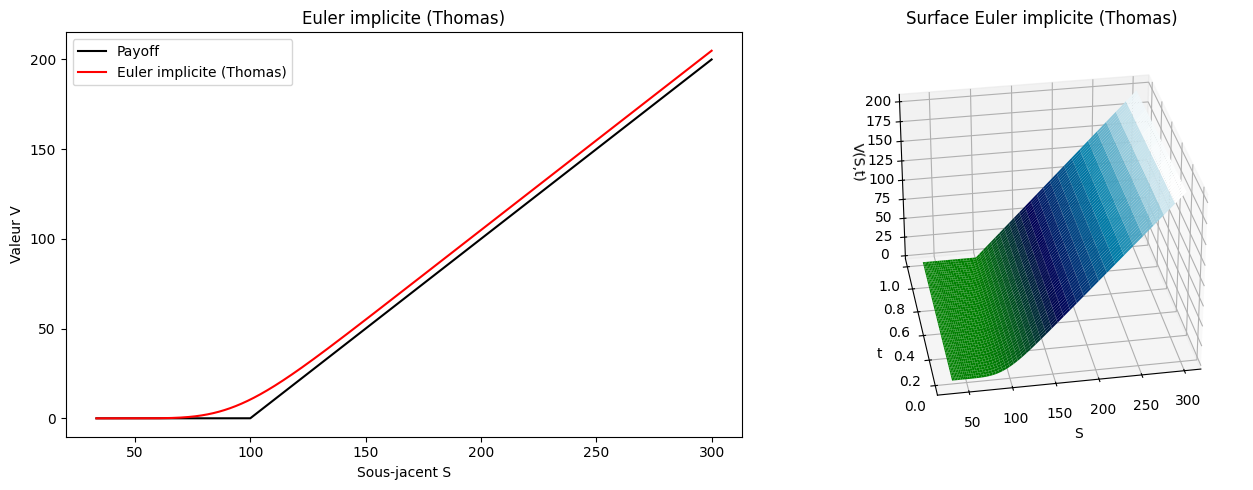

Euler explicite → Prix = 10.451575


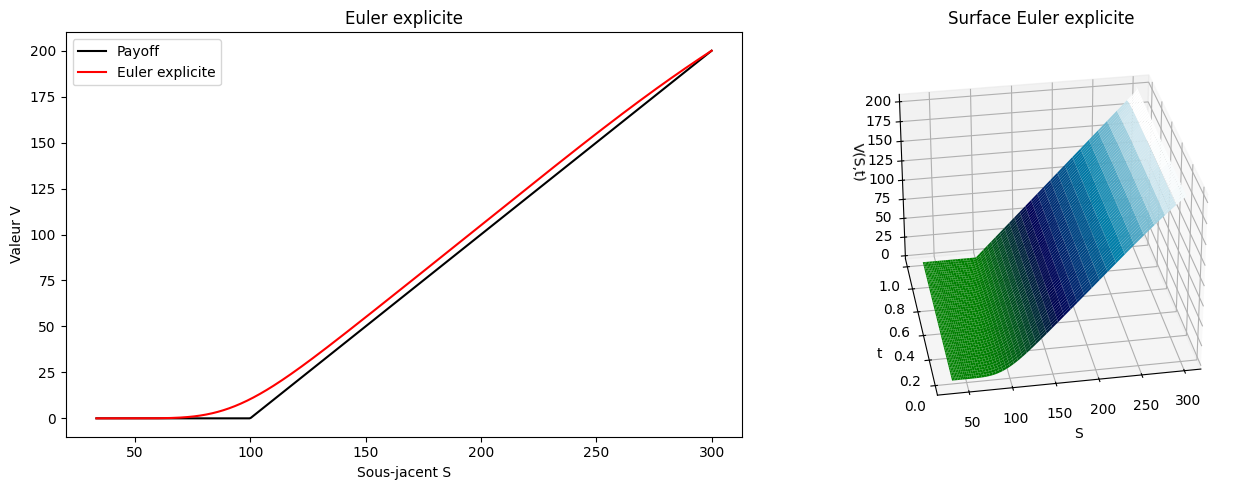

Crank–Nicolson + Rannacher : 10.446186


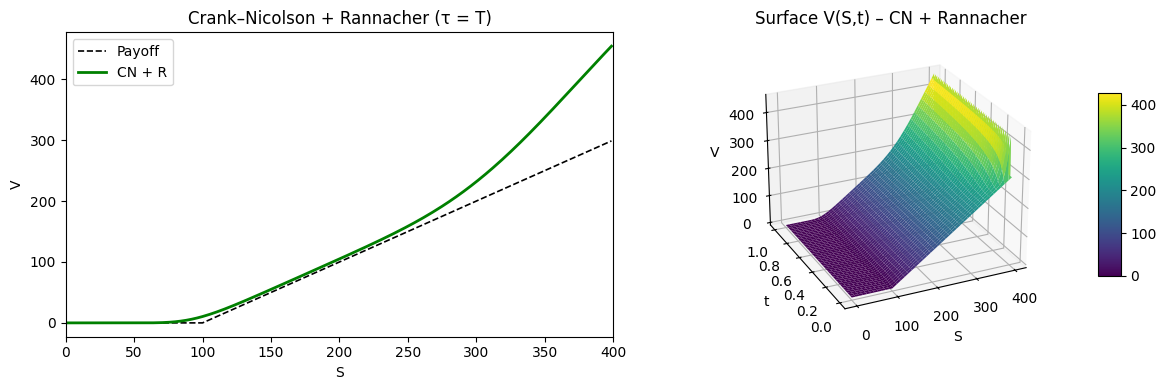

Monte Carlo (moyenne) = 10.450318 | SE = 0.019000 | IC95% = [10.413077, 10.487558]

Écart absolu vs M (N fixe)
     M |         EE |         EI |       CN+R
--------------------------------------------
   200 |   0.012561 |   0.002037 |   0.015980
   500 |   0.009397 |   0.005199 |   0.016062
  1000 |   0.008346 |   0.006249 |   0.016074
  2000 |   0.007822 |   0.006774 |   0.016077
  3000 |   0.007647 |   0.006948 |   0.016077

Écart absolu vs N (M fixe)
     N |         EE |         EI |       CN+R
--------------------------------------------
    80 |   0.025818 |   0.024775 |   0.062220
   120 |   0.011815 |   0.010768 |   0.027322
   150 |   0.007822 |   0.006774 |   0.016077
   200 |   0.004732 |   0.003683 |   0.009633
   300 |   0.002537 |   0.001487 |   0.004130


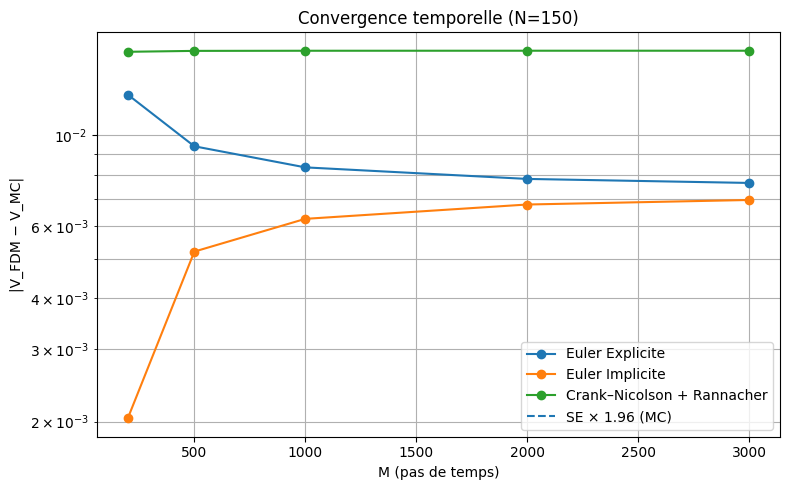

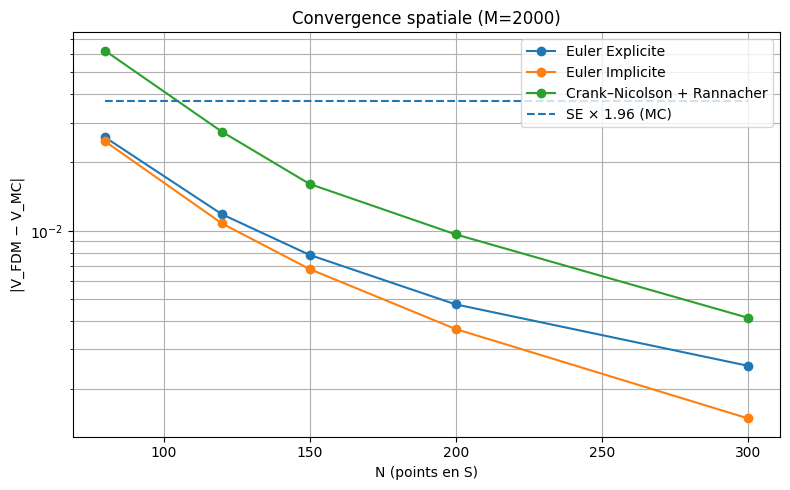

In [3]:
if __name__ == "__main__":

    pricer = EuropeanOptionPricer(S0=100, K=100, T=1, r=0.05, sigma=0.2)

    mc_mean, mc_se, mc_ci = pricer.price_monte_carlo(n_paths=600_000, seed=7)
    print(f"Monte Carlo : {mc_mean:.6f}  | IC95% = [{mc_ci[0]:.6f}, {mc_ci[1]:.6f}]")

    price_imp, S_imp, V_imp = pricer.price_implicit(N=3000, M=2000)
    print(f"Euler implicite (Thomas) → Prix = {price_imp:.6f}")
    pricer.plot_surface(S_imp, V_imp, pricer.T, "Euler implicite (Thomas)")

    price_exp, S_exp, V_exp = pricer.price_explicit(N=400, M=100000)
    print(f"Euler explicite → Prix = {price_exp:.6f}")
    pricer.plot_surface(S_exp, V_exp, pricer.T, "Euler explicite")

    px_cn, S, V_all = pricer.price_cn_rannacher(N=300, M=1200, rannacher_steps=4)
    print(f"Crank–Nicolson + Rannacher : {px_cn:.6f}")

    fig = plt.figure(figsize=(12, 4))
    ax1 = fig.add_subplot(1, 2, 1)
    ax1.plot(S[:-1], np.maximum(S[:-1]-pricer.K,0), 'k--', lw=1.2, label='Payoff')
    ax1.plot(S[:-1], V_all[-1, :-1], 'g-', lw=2, label='CN + R')
    ax1.set_xlim(0, S[-1])
    ax1.set_xlabel('S')
    ax1.set_ylabel('V')
    ax1.legend()
    ax1.set_title('Crank–Nicolson + Rannacher (τ = T)')

    TT, SS = np.meshgrid(np.linspace(0, pricer.T, V_all.shape[0]), S)
    ax2 = fig.add_subplot(1, 2, 2, projection='3d')
    surf = ax2.plot_surface(SS, TT, V_all.T, cmap=cm.viridis, linewidth=0, antialiased=True)
    ax2.set_xlabel('S')
    ax2.set_ylabel('t')
    ax2.set_zlabel('V')
    ax2.set_title('Surface V(S,t) – CN + Rannacher')
    ax2.view_init(25, -115)
    fig.colorbar(surf, ax=ax2, shrink=0.6, aspect=8, pad=0.1)
    plt.tight_layout()
    plt.show()

    pricer.analyze_convergence()

    



=== Paramètres Merton ===
S0=100, K=100, T=1, r=0.05, sigma=0.2, lambda=0.1, m=-0.1, delta=0.2

=== Prix ===
Formule fermée (Merton) : 10.724590
Monte Carlo (200k)      : 10.787329
IMEX Euler FDM          : 10.805216
IMEX CN (+Rannacher)    : 10.806078


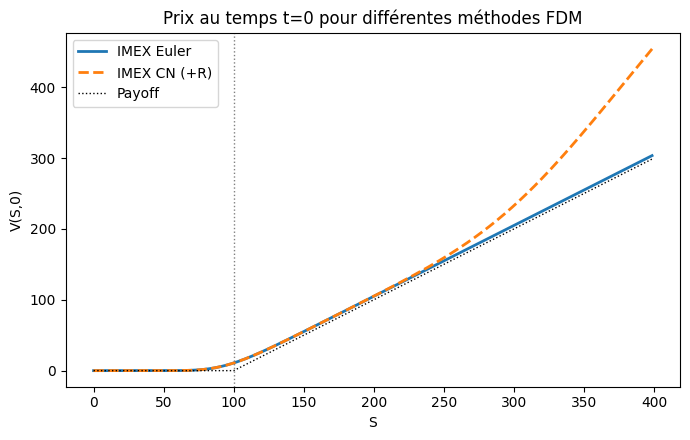

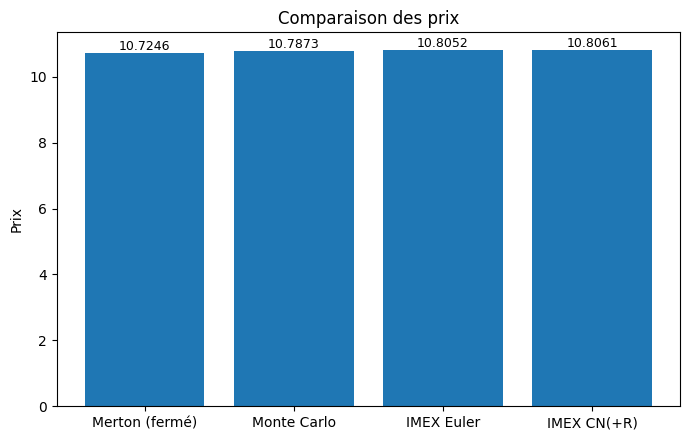

In [4]:
# Merton Jump-Diffusion (hérite de BS)

class EuropeanOptionMerton:
    """
    Pricing d'une option européenne sous le modèle de Merton (sauts de Poisson).
    Hérite des méthodes de base (Thomas solver, etc.) via EuropeanOptionPricer.
    """

    def __init__(self, S0, K, T, r, sigma, lam, m, delta, option_type='call'):
        self.S0 = S0
        self.K = K
        self.T = T
        self.r = r
        self.sigma = sigma
        self.lam = lam
        self.m = m
        self.delta = delta
        self.option_type = option_type.lower()

    # Black-Scholes pour le cas sans sauts
    def bs_call_price(self, S0, K, T, r, sigma):
        if T <= 0:
            return max(S0 - K, 0.0)
        if sigma <= 0:
            return np.exp(-r*T) * max(S0*np.exp(r*T) - K, 0.0)
        d1 = (np.log(S0/K) + (r + 0.5*sigma**2)*T) / (sigma*np.sqrt(T))
        d2 = d1 - sigma*np.sqrt(T)
        return S0*norm.cdf(d1) - K*np.exp(-r*T)*norm.cdf(d2)

    # Solveur tridiagonal (Thomas)
    def thomas_solver(self, a, b, c, d):
        n = len(d)
        ac, bc, cc, dc = a.copy(), b.copy(), c.copy(), d.copy()
        for i in range(1, n):
            w = ac[i] / bc[i-1]
            bc[i] -= w * cc[i-1]
            dc[i] -= w * dc[i-1]
        x = np.empty(n)
        x[-1] = dc[-1] / bc[-1]
        for i in range(n-2, -1, -1):
            x[i] = (dc[i] - cc[i] * x[i+1]) / bc[i]
        return x

    # Formule fermée de Merton
    def merton_call_closed_form(self, n_max=50, tol=1e-12):
        S0, K, T, r, sigma, lam, m, delta = (
            self.S0, self.K, self.T, self.r, self.sigma, self.lam, self.m, self.delta
        )
        kappa = np.exp(m + 0.5*delta**2) - 1.0
        price = 0.0
        for n in range(n_max+1):
            w_n = np.exp(-lam*T) * (lam*T)**n / math.factorial(n)
            if w_n < tol and n > 5:
                break
            r_n = r - lam*kappa + (n * m) / T
            sigma_n = np.sqrt(sigma**2 + (n * delta**2) / T)
            price += w_n * self.bs_call_price(S0, K, T, r_n, sigma_n)
        return price

    # Monte Carlo sous Merton (exact)
    def mc_merton_call(self, n_paths=200_000, seed=42):
        S0, K, T, r, sigma, lam, m, delta = (
            self.S0, self.K, self.T, self.r, self.sigma, self.lam, self.m, self.delta
        )
        rng = np.random.default_rng(seed)
        kappa = np.exp(m + 0.5*delta**2) - 1.0
        N = rng.poisson(lam*T, size=n_paths)
        W = rng.normal(0.0, 1.0, size=n_paths)
        drift = (r - lam*kappa - 0.5*sigma**2)*T + sigma*np.sqrt(T)*W
        Y_sum = np.zeros(n_paths)
        idx = np.where(N > 0)[0]
        if idx.size > 0:
            total_jumps = N[idx].sum()
            Y_all = rng.normal(m, delta, size=total_jumps)
            start = 0
            for k, path in enumerate(idx):
                cnt = N[path]
                Y_sum[path] = Y_all[start:start+cnt].sum()
                start += cnt
        ST = S0 * np.exp(drift + Y_sum)
        payoff = np.maximum(ST - K, 0.0)
        return np.exp(-r*T) * payoff.mean()

    # Coefficients diffusion pour IMEX FDM
    def build_diffusion_coeffs(self, S, dt, r_eff, sigma):
        N = len(S) - 1
        dS = S[1] - S[0]
        Si = S[1:N]
        a = 0.5*dt*((sigma**2)*(Si**2)/(dS**2) - r_eff*Si/dS)
        c = 0.5*dt*((sigma**2)*(Si**2)/(dS**2) + r_eff*Si/dS)
        lam = dt*((sigma**2)*(Si**2)/(dS**2) + self.r)
        return a, c, lam

    # Terme de saut explicite (Gauss-Hermite)
    def jump_explicit_term(self, V, S, tau, gh_n=20):
        K, r, lam, m, delta = self.K, self.r, self.lam, self.m, self.delta
        x, w = hermgauss(gh_n)
        wk = w / np.sqrt(np.pi)
        yk = m + np.sqrt(2.0)*delta*x
        jk = np.exp(yk)
        Smax = S[-1]
        V_jump = np.zeros_like(V)
        for j, wj in zip(jk, wk):
            Sj = j * S
            vj = np.interp(Sj, S, V, left=0.0, right=0.0)
            idx_right = Sj > Smax
            if np.any(idx_right):
                vj[idx_right] = Sj[idx_right] - K*np.exp(-r*tau)
            V_jump += wj * (vj - V)
        return lam * V_jump


    # IMEX Euler (diff implicite, saut explicite)
    def fdm_imex_euler_call(self, Smax=400.0, N=400, M=1200):
        S0, K, T, r, sigma, lam, m, delta = (
            self.S0, self.K, self.T, self.r, self.sigma, self.lam, self.m, self.delta
        )
        S = np.linspace(0.0, Smax, N+1)
        dt = T / M
        V = np.maximum(S - K, 0.0)
        kappa = np.exp(m + 0.5*delta**2) - 1.0
        r_eff = r - lam*kappa
        a, c, lam_vec = self.build_diffusion_coeffs(S, dt, r_eff, sigma)
        lower = -a[1:]; main = 1.0 + lam_vec; upper = -c[:-1]
        tau = 0.0
        for _ in range(M):
            tau_n1 = tau + dt
            VL, VR = 0.0, Smax - K*np.exp(-r*tau_n1)
            Jn = self.jump_explicit_term(V, S, tau)
            rhs = V[1:-1] + dt * Jn[1:-1]
            rhs[0]  += a[0]*VL
            rhs[-1] += c[-1]*VR
            V[1:-1] = self.thomas_solver(
                np.concatenate(([0.0], lower)), main.copy(),
                np.concatenate((upper, [0.0])), rhs
            )
            V[0], V[-1] = VL, VR
            tau = tau_n1
        price = np.interp(S0, S, V)
        return price, S, V

    # IMEX Crank–Nicolson + Rannacher
    def fdm_imex_cn_call(self, Smax=400.0, N=400, M=1200, rannacher_steps=2):
        S0, K, T, r, sigma, lam, m, delta = (
            self.S0, self.K, self.T, self.r, self.sigma, self.lam, self.m, self.delta
        )
        S = np.linspace(0.0, Smax, N+1)
        dt = T / M
        V = np.maximum(S - K, 0.0)
        kappa = np.exp(m + 0.5*delta**2) - 1.0
        r_eff = r - lam*kappa
        a, c, lam_vec = self.build_diffusion_coeffs(S, dt, r_eff, sigma)
        tau = 0.0
        for n_step in range(M):
            tau_n1 = tau + dt
            VL, VR = 0.0, Smax - K*np.exp(-r*tau_n1)
            if n_step < rannacher_steps:
                lower = -a[1:]; main = 1.0 + lam_vec; upper = -c[:-1]
                Jn = self.jump_explicit_term(V, S, tau)
                rhs = V[1:-1] + dt * Jn[1:-1]
                rhs[0]  += a[0]*VL; rhs[-1] += c[-1]*VR
                V[1:-1] = self.thomas_solver(
                    np.concatenate(([0.0], lower)), main.copy(),
                    np.concatenate((upper, [0.0])), rhs
                )
            else:
                lowerL=-0.5*a[1:]; mainL=1.0+0.5*lam_vec; upperL=-0.5*c[:-1]
                diff_rhs = 0.5*a*V[0:-2] + (1.0-0.5*lam_vec)*V[1:-1] + 0.5*c*V[2:]
                Jn = self.jump_explicit_term(V, S, tau)
                rhs = diff_rhs + dt*Jn[1:-1]
                rhs[0]  += 0.5*a[0]*(V[0]+VL)
                rhs[-1] += 0.5*c[-1]*(V[-1]+VR)
                V[1:-1] = self.thomas_solver(
                    np.concatenate(([0.0], lowerL)), mainL.copy(),
                    np.concatenate((upperL, [0.0])), rhs
                )
            V[0], V[-1] = VL, VR
            tau = tau_n1
        price = np.interp(S0, S, V)
        return price, S, V

    def run_comparison(self, Smax=400.0, N=300, M=1200):
        px_merton = self.merton_call_closed_form()
        px_mc = self.mc_merton_call()
        px_euler, S_e, V_e = self.fdm_imex_euler_call(Smax=Smax, N=N, M=M)
        px_cn, S_c, V_c = self.fdm_imex_cn_call(Smax=Smax, N=N, M=M)

        print("=== Paramètres Merton ===")
        print(f"S0={self.S0}, K={self.K}, T={self.T}, r={self.r}, sigma={self.sigma}, "
              f"lambda={self.lam}, m={self.m}, delta={self.delta}")
        print("\n=== Prix ===")
        print(f"Formule fermée (Merton) : {px_merton:.6f}")
        print(f"Monte Carlo (200k)      : {px_mc:.6f}")
        print(f"IMEX Euler FDM          : {px_euler:.6f}")
        print(f"IMEX CN (+Rannacher)    : {px_cn:.6f}")


        plt.figure(figsize=(7,4.5))
        plt.plot(S_e[:-1], V_e[:-1], label="IMEX Euler", lw=2)
        plt.plot(S_c[:-1], V_c[:-1], label="IMEX CN (+R)", lw=2, ls="--")
        plt.plot(S_e[:-1], np.maximum(S_e[:-1]-self.K, 0.0), 'k:', lw=1, label="Payoff")
        plt.axvline(self.S0, color='gray', lw=1, ls=':')
        plt.title("Prix au temps t=0 pour différentes méthodes FDM")
        plt.xlabel("S"); plt.ylabel("V(S,0)")
        plt.legend(); plt.tight_layout(); plt.show()

        # Graphique 2 pour comparer les méthodes
        names = ["Merton (fermé)", "Monte Carlo", "IMEX Euler", "IMEX CN(+R)"]
        vals  = [px_merton, px_mc, px_euler, px_cn]
        plt.figure(figsize=(7,4.5))
        bars = plt.bar(names, vals)
        for b,v in zip(bars, vals):
            plt.text(b.get_x()+b.get_width()/2, v, f"{v:.4f}", ha='center', va='bottom', fontsize=9)
        plt.ylabel("Prix")
        plt.title("Comparaison des prix")
        plt.tight_layout(); plt.show()







if __name__ == "__main__":
    merton = EuropeanOptionMerton(S0=100, K=100, T=1, r=0.05, sigma=0.2,
                                  lam=0.1, m=-0.1, delta=0.2)
    merton.run_comparison()



 Résumé des prix du put américain :
Option européenne (Black–Scholes)  : 5.573526
Option américaine (PDE splitting)  : 6.089844
Option américaine (LSM Monte Carlo): 6.068546


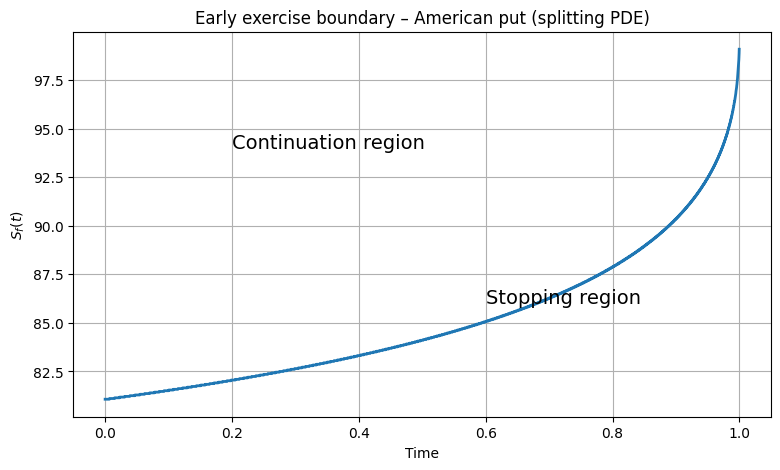

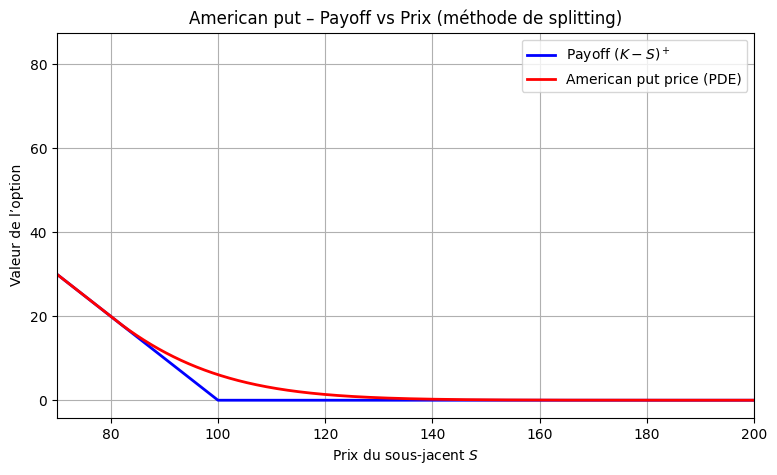

In [5]:
class AmericanPutPricer:
    """
    Version simplifiée de BS_pricer pour un put américain sous Black–Scholes :
    - PDE implicite en log(S) avec splitting (projection)
    - LSM Monte Carlo
    """

    def __init__(self, S0, K, T, r, sigma):
        self.S0 = S0
        self.K = K
        self.T = T
        self.r = r
        self.sig = sigma

        self.S_vec = None
        self.mesh = None
        self.price_vec = None
        self.price = None

    def payoff_f(self, S):
        return np.maximum(self.K - S, 0.0)

    def european_bs(self):
        d1 = (np.log(self.S0/self.K) + (self.r + 0.5*self.sig**2)*self.T)/(self.sig*np.sqrt(self.T))
        d2 = d1 - self.sig*np.sqrt(self.T)
        return self.K*np.exp(-self.r*self.T)*ss.norm.cdf(-d2) - self.S0*ss.norm.cdf(-d1)

    def PDE_price(self, Nspace=800, Ntime=500, solver="splu"):
        S_max = 6.0 * float(self.K)
        S_min = float(self.K) / 6.0
        x_max = np.log(S_max)
        x_min = np.log(S_min)
        x0 = np.log(self.S0)

        x, dx = np.linspace(x_min, x_max, Nspace, retstep=True)
        t, dt = np.linspace(0, self.T, Ntime, retstep=True)

        self.S_vec = np.exp(x)
        Payoff = self.payoff_f(self.S_vec)

        V = np.zeros((Nspace, Ntime))
        V[:, -1] = Payoff
        V[-1, :] = 0.0
        V[0, :] = Payoff[0] * np.exp(-self.r * t[::-1])

        sig2 = self.sig**2
        dxx = dx**2
        a = (dt / 2.0) * ((self.r - 0.5 * sig2) / dx - sig2 / dxx)
        b = 1.0 + dt * (sig2 / dxx + self.r)
        c = -(dt / 2.0) * ((self.r - 0.5 * sig2) / dx + sig2 / dxx)

        D = sparse.diags([a, b, c], [-1, 0, 1], shape=(Nspace - 2, Nspace - 2)).tocsc()
        offset = np.zeros(Nspace - 2)

        DD = splu(D) if solver == "splu" else None
        for i in range(Ntime - 2, -1, -1):
            offset[0] = a * V[0, i]
            offset[-1] = c * V[-1, i]
            V_temp = DD.solve(V[1:-1, i+1] - offset) if DD else spsolve(D, V[1:-1, i+1] - offset)
            V[1:-1, i] = np.maximum(V_temp, Payoff[1:-1])

        self.mesh = V
        self.price_vec = V[:, 0]
        self.price = np.interp(x0, x, V[:, 0])
        self.Nspace = Nspace
        self.Ntime = Ntime
        return self.price

    def LSM_price(self, N_steps=120, N_paths=100_000, order=2, seed=42):
        np.random.seed(seed)
        dt = self.T / (N_steps - 1)
        df = np.exp(-self.r * dt)

        Z = np.random.normal(0, 1, (N_paths, N_steps-1))
        logS = np.cumsum((self.r - 0.5*self.sig**2)*dt + self.sig*np.sqrt(dt)*Z, axis=1)
        logS = np.hstack((np.zeros((N_paths, 1)), logS))
        S = self.S0 * np.exp(logS)

        H = np.maximum(self.K - S, 0.0)
        V = np.zeros_like(H)
        V[:, -1] = H[:, -1]

        for t in range(N_steps-2, 0, -1):
            itm = H[:, t] > 0
            X = S[itm, t]
            Y = V[itm, t+1] * df
            if len(X) > 3:
                coef = np.polyfit(X, Y, deg=order)
                C = np.polyval(coef, X)
                exercise = H[itm, t] > C
                V[itm, t] = np.where(exercise, H[itm, t], V[itm, t+1]*df)
                V[~itm, t] = V[~itm, t+1]*df

        return np.mean(V[:, 1]) * df
    
    def PDE_NewtonHoward(self, Nspace=800, Ntime=500, tol=1e-6, max_iter=50, solver="splu", verbose=True):
        """Newton-Howard policy iteration for American put pricing (finite-difference PDE)."""

        S_max = 6.0 * float(self.K)
        S_min = float(self.K) / 6.0
        x_max = np.log(S_max)
        x_min = np.log(S_min)
        x0 = np.log(self.S0)

        x, dx = np.linspace(x_min, x_max, Nspace, retstep=True)
        t, dt = np.linspace(0, self.T, Ntime, retstep=True)

        self.S_vec = np.exp(x)
        payoff = self.payoff_f(self.S_vec)

        V = np.zeros((Nspace, Ntime))
        V[:, -1] = payoff
        V[-1, :] = 0.0
        V[0, :] = payoff[0] * np.exp(-self.r * t[::-1])

        sig2 = self.sig**2
        dxx = dx**2
        a = (dt / 2.0) * ((self.r - 0.5 * sig2) / dx - sig2 / dxx)
        b = 1.0 + dt * (sig2 / dxx + self.r)
        c = -(dt / 2.0) * ((self.r - 0.5 * sig2) / dx + sig2 / dxx)

        D = sparse.diags([a, b, c], [-1, 0, 1], shape=(Nspace - 2, Nspace - 2)).tocsc()

        if solver == "splu":
            LU = splu(D)

        offset = np.zeros(Nspace - 2)

        for i in range(Ntime - 2, -1, -1):
            offset[0]  = a * V[0, i]
            offset[-1] = c * V[-1, i]

            #splitting simple (point de départ)
            V_temp = LU.solve(V[1:-1, i+1] - offset) if solver == "splu" else spsolve(D, V[1:-1, i+1] - offset)
            V_old = np.maximum(V_temp, payoff[1:-1])

            # Newton–Howard iteration
            for it in range(max_iter):
                if solver == "splu":
                    V_temp = LU.solve(V[1:-1, i+1] - offset)
                else:
                    V_temp = spsolve(D, V[1:-1, i+1] - offset)

                # Application de la contrainte : V >= payoff
                V_new = np.maximum(V_temp, payoff[1:-1])

                err = np.max(np.abs(V_new - V_old))
                if err < tol:
                    break

                # mise à jour pour la prochaine itération
                V_old = V_new


            V[1:-1, i] = V_new
            if verbose:
                print(f"Step {i:4d} | Iterations = {it+1:2d} | Error = {err:.2e}")

        self.mesh = V
        self.price_vec = V[:, 0]
        self.price = np.interp(x0, x, V[:, 0])

        return self.price, it + 1
    
        



AP = AmericanPutPricer(S0=100, K=100, T=1.0, r=0.05, sigma=0.2)
N_space, N_time = 8000, 5000

price_PDE = AP.PDE_price(Nspace=N_space, Ntime=N_time)
price_LSM = AP.LSM_price(N_steps=120, N_paths=50_000)
price_EU = AP.european_bs()

print("\n Résumé des prix du put américain :")
print(f"Option européenne (Black–Scholes)  : {price_EU:.6f}")
print(f"Option américaine (PDE splitting)  : {price_PDE:.6f}")
print(f"Option américaine (LSM Monte Carlo): {price_LSM:.6f}")


payoff = AP.payoff_f(AP.S_vec).reshape(-1, 1)
mesh = (AP.mesh - payoff)[1:-1, :-1]  # sans les bords
optimal_indices = np.argmax(np.abs(mesh) > 1e-10, axis=0)

T_vec = np.linspace(0, AP.T, AP.Ntime)
S_boundary = AP.S_vec[1:-1][optimal_indices]

plt.figure(figsize=(9, 5))
plt.plot(T_vec[:-1], S_boundary, lw=2)
plt.text(0.2, 0.94*AP.K, "Continuation region", fontsize=14)
plt.text(0.6, 0.86*AP.K, "Stopping region", fontsize=14)
plt.xlabel("Time")
plt.ylabel("$S_f(t)$")
plt.title("Early exercise boundary – American put (splitting PDE)")
plt.grid(True)
plt.show()

payoff = AP.payoff_f(AP.S_vec)
plt.figure(figsize=(9,5))
plt.plot(AP.S_vec, payoff, color='blue', lw=2, label="Payoff $(K - S)^+$")
plt.plot(AP.S_vec, AP.price_vec, color='red', lw=2, label="American put price (PDE)")
plt.xlim(70, 200)
plt.xlabel("Prix du sous-jacent $S$")
plt.ylabel("Valeur de l’option")
plt.title("American put – Payoff vs Prix (méthode de splitting)")
plt.legend()
plt.grid(True)
plt.show()

In [6]:
price_NH, iters = AP.PDE_NewtonHoward(Nspace=800, Ntime=500, tol=1e-8, max_iter=20)
print(f"\nPrix (Newton–Howard) : {price_NH:.5f}  —  Convergence en {iters} itérations")

Step  498 | Iterations =  1 | Error = 0.00e+00
Step  497 | Iterations =  1 | Error = 0.00e+00
Step  496 | Iterations =  1 | Error = 0.00e+00
Step  495 | Iterations =  1 | Error = 0.00e+00
Step  494 | Iterations =  1 | Error = 0.00e+00
Step  493 | Iterations =  1 | Error = 0.00e+00
Step  492 | Iterations =  1 | Error = 0.00e+00
Step  491 | Iterations =  1 | Error = 0.00e+00
Step  490 | Iterations =  1 | Error = 0.00e+00
Step  489 | Iterations =  1 | Error = 0.00e+00
Step  488 | Iterations =  1 | Error = 0.00e+00
Step  487 | Iterations =  1 | Error = 0.00e+00
Step  486 | Iterations =  1 | Error = 0.00e+00
Step  485 | Iterations =  1 | Error = 0.00e+00
Step  484 | Iterations =  1 | Error = 0.00e+00
Step  483 | Iterations =  1 | Error = 0.00e+00
Step  482 | Iterations =  1 | Error = 0.00e+00
Step  481 | Iterations =  1 | Error = 0.00e+00
Step  480 | Iterations =  1 | Error = 0.00e+00
Step  479 | Iterations =  1 | Error = 0.00e+00
Step  478 | Iterations =  1 | Error = 0.00e+00
Step  477 | I

Prix américain (PDE splitting) : 6.0898

=== Comparaison Longstaff–Schwartz vs PDE ===
Prix PDE splitting : 6.08984
Moyenne LSM        : 6.07131
Écart-type LSM     : 0.04382
Min / Max          : 5.95607 / 6.18983


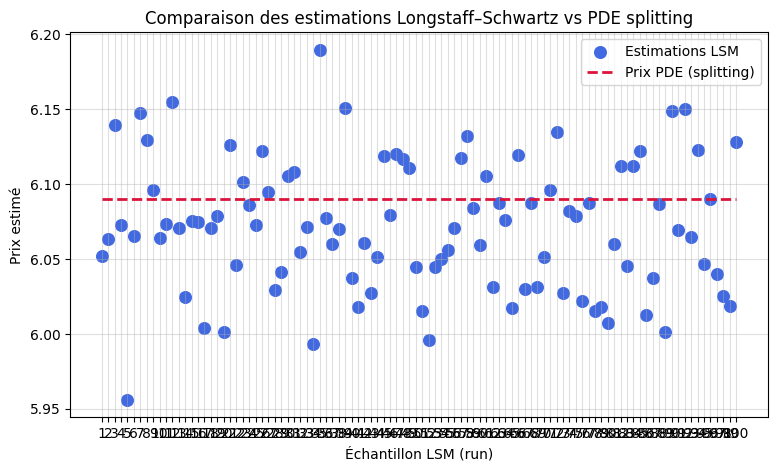

In [7]:
AP = AmericanPutPricer(S0=100, K=100, T=1.0, r=0.05, sigma=0.2)
N_space, N_time = 8000, 5000

price_PDE = AP.PDE_price(Nspace=N_space, Ntime=N_time)
print(f"Prix américain (PDE splitting) : {price_PDE:.4f}")

n_samples = 100
prices_LSM = []

for k in range(n_samples):
    seed = 100 + k  
    price = AP.LSM_price(N_steps=120, N_paths=20_000, order=2, seed=seed)
    prices_LSM.append(price)

prices_LSM = np.array(prices_LSM)

print("\n=== Comparaison Longstaff–Schwartz vs PDE ===")
print(f"Prix PDE splitting : {price_PDE:.5f}")
print(f"Moyenne LSM        : {prices_LSM.mean():.5f}")
print(f"Écart-type LSM     : {prices_LSM.std():.5f}")
print(f"Min / Max          : {prices_LSM.min():.5f} / {prices_LSM.max():.5f}")

plt.figure(figsize=(9, 5))
plt.scatter(range(1, n_samples + 1), prices_LSM, color='royalblue', s=70, label='Estimations LSM')
plt.hlines(price_PDE, 1, n_samples, colors='crimson', linestyles='--', lw=2, label='Prix PDE (splitting)')
plt.xticks(range(1, n_samples + 1))
plt.xlabel("Échantillon LSM (run)")
plt.ylabel("Prix estimé")
plt.title("Comparaison des estimations Longstaff–Schwartz vs PDE splitting")
plt.grid(True, alpha=0.4)
plt.legend()
plt.show()

Prix américain (PDE splitting) : 6.08562

=== Comparaison Newton–Howard vs Longstaff–Schwartz ===
Prix PDE splitting        : 6.08562
Moyenne Newton–Howard     : 6.08562
Moyenne LSM               : 6.07131
Écart-type LSM            : 0.04382
Min/Max LSM               : 5.95607 / 6.18983


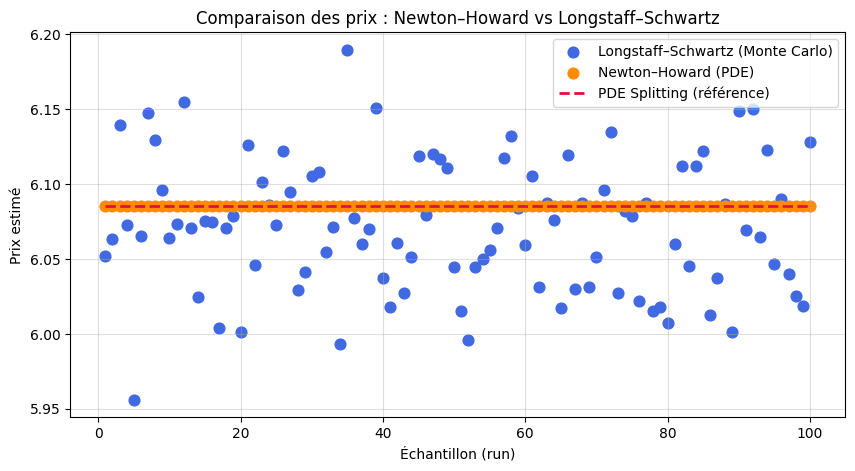

In [8]:
AP = AmericanPutPricer(S0=100, K=100, T=1.0, r=0.05, sigma=0.2)
N_space, N_time = 800, 500

price_PDE = AP.PDE_price(Nspace=N_space, Ntime=N_time)
print(f"Prix américain (PDE splitting) : {price_PDE:.5f}")

n_samples = 100
prices_NH = []
for k in range(n_samples):
    price_NH, iters = AP.PDE_NewtonHoward(
        Nspace=N_space,
        Ntime=N_time,
        tol=1e-8,
        max_iter=20,
        solver="splu",
        verbose=False
    )
    prices_NH.append(price_NH)
prices_NH = np.array(prices_NH)

prices_LSM = []
for k in range(n_samples):
    seed = 100 + k
    price = AP.LSM_price(N_steps=120, N_paths=20_000, order=2, seed=seed)
    prices_LSM.append(price)
prices_LSM = np.array(prices_LSM)

print("\n=== Comparaison Newton–Howard vs Longstaff–Schwartz ===")
print(f"Prix PDE splitting        : {price_PDE:.5f}")
print(f"Moyenne Newton–Howard     : {prices_NH.mean():.5f}")
print(f"Moyenne LSM               : {prices_LSM.mean():.5f}")
print(f"Écart-type LSM            : {prices_LSM.std():.5f}")
print(f"Min/Max LSM               : {prices_LSM.min():.5f} / {prices_LSM.max():.5f}")

plt.figure(figsize=(10, 5))
plt.scatter(range(1, n_samples + 1), prices_LSM, color='royalblue', s=60, label='Longstaff–Schwartz (Monte Carlo)')
plt.scatter(range(1, n_samples + 1), prices_NH, color='darkorange', s=60, label='Newton–Howard (PDE)')
plt.hlines(price_PDE, 1, n_samples, colors='crimson', linestyles='--', lw=2, label='PDE Splitting (référence)')

plt.xlabel("Échantillon (run)")
plt.ylabel("Prix estimé")
plt.title("Comparaison des prix : Newton–Howard vs Longstaff–Schwartz")
plt.legend()
plt.grid(alpha=0.4)
plt.show()

In [9]:
class AmericanPutMerton(AmericanPutPricer):
    """
    Extension de la classe AmericanPutPricer au modèle de Merton (diffusion + sauts).
    Implémente :
      - PDE IMEX (diffusion implicite, sauts explicites) + splitting (projection)
      - Simulation Monte Carlo (Merton process)
      - Longstaff-Schwartz Monte Carlo (LSM)
    """

    def __init__(self, S0, K, T, r, sigma, lamb, m, delta):
        super().__init__(S0, K, T, r, sigma)
        self.lamb = lamb     # intensité des sauts
        self.m = m           # moyenne log du saut
        self.delta = delta   # écart-type log du saut
        self.kappa = np.exp(m + 0.5 * delta**2) - 1  # E[J - 1]

    # INTÉGRALE DE SAUT (approximation de Gauss-Legendre)
    def jump_integral(self, V, S_vec, nodes, weights):
        """
        Calcule λ * (V - EV_jump) avec quadrature de Gauss–Legendre :
        EV_jump(s) = ∫ V(s * e^Y) g(Y) dY,  Y ~ N(m, δ²)
        """
        Nj = len(nodes)
        EV_jump = np.zeros_like(V)
        for j in range(Nj):
            J = np.exp(self.m + np.sqrt(2) * self.delta * nodes[j])
            Sj = J * S_vec
            Vj = np.interp(Sj, S_vec, V, left=V[0], right=0.0)
            EV_jump += weights[j] * Vj
        EV_jump /= np.sqrt(np.pi)
        return self.lamb * (V - EV_jump)

    # PDE IMEX + SPLITTING
    def PDE_IMEX_splitting(self, Nspace=600, Ntime=400, Nquad=20, solver="splu", verbose=False):
        """
        Schéma IMEX (diffusion implicite + sauts explicites)
        combiné à la projection de splitting pour la contrainte V >= payoff.
        """
        # Grille logarithmique
        S_max, S_min = 6 * self.K, self.K / 6
        x_max, x_min = np.log(S_max), np.log(S_min)
        x0 = np.log(self.S0)
        x, dx = np.linspace(x_min, x_max, Nspace, retstep=True)
        t, dt = np.linspace(0, self.T, Ntime, retstep=True)
        S_vec = np.exp(x)
        payoff = self.payoff_f(S_vec)

        # Conditions initiales et aux bords
        V = np.zeros((Nspace, Ntime))
        V[:, -1] = payoff
        V[0, :] = self.K * np.exp(-self.r * (self.T - t))
        V[-1, :] = 0.0

        # Coefficients du schéma implicite 
        sig2, dxx = self.sig**2, dx**2
        a = (dt / 2) * ((self.r - self.lamb * self.kappa - 0.5 * sig2) / dx - sig2 / dxx)
        b = 1 + dt * (sig2 / dxx + self.r)
        c = -(dt / 2) * ((self.r - self.lamb * self.kappa - 0.5 * sig2) / dx + sig2 / dxx)

        A = sparse.diags([a, b, c], [-1, 0, 1], shape=(Nspace - 2, Nspace - 2)).tocsc()
        LU = splu(A) if solver == "splu" else None

        nodes, weights = leggauss(Nquad)
        offset = np.zeros(Nspace - 2)

        # Boucle backward temporelle
        for i in range(Ntime - 2, -1, -1):
            # Terme de saut explicite
            jump_term = self.jump_integral(V[:, i+1], S_vec, nodes, weights)

            # Bord gauche , droite
            offset[0] = a * V[0, i]
            offset[-1] = c * V[-1, i]

            RHS = V[1:-1, i+1] - offset + dt * jump_term[1:-1]
            V_temp = LU.solve(RHS) if solver == "splu" else spsolve(A, RHS)

            # splitting
            V[1:-1, i] = np.maximum(V_temp, payoff[1:-1])

            if verbose and i % 50 == 0:
                print(f"Step {i:4d}/{Ntime} done")

        self.S_vec = S_vec
        self.mesh = V
        self.price_vec = V[:, 0]
        self.price = np.interp(x0, x, V[:, 0])
        return self.price

    # Processus de Merton
    def simulate_paths_merton(self, N_paths=100_000, N_steps=100, seed=42):
        """
        Simule des trajectoires du processus de Merton :
        dS/S = (r - λκ)dt + σ dW_t + (J - 1)dq_t
        """
        np.random.seed(seed)
        dt = self.T / N_steps
        Z = np.random.normal(0, 1, (N_paths, N_steps))
        N = np.random.poisson(self.lamb * dt, size=(N_paths, N_steps))
        Y = np.random.normal(self.m, self.delta, size=(N_paths, N_steps))

        logS = np.zeros((N_paths, N_steps + 1))
        for t in range(N_steps):
            logJ = N[:, t] * Y[:, t]
            drift = (self.r - self.lamb * self.kappa - 0.5 * self.sig**2) * dt
            diffusion = self.sig * np.sqrt(dt) * Z[:, t]
            logS[:, t+1] = logS[:, t] + drift + diffusion + logJ
        S = self.S0 * np.exp(logS)
        return S

    # LSM
    def LSM_price(self, N_paths=100_000, N_steps=100, order=2, seed=42):
        """
        Prix du put américain via Monte Carlo de Longstaff–Schwartz
        (approximation de la valeur de continuation par régression polynomiale).
        """
        S = self.simulate_paths_merton(N_paths=N_paths, N_steps=N_steps, seed=seed)
        dt = self.T / N_steps
        df = np.exp(-self.r * dt)

        H = np.maximum(self.K - S, 0.0)
        V = np.zeros_like(H)
        V[:, -1] = H[:, -1]

        for t in range(N_steps - 2, 0, -1):
            itm = H[:, t] > 1e-12
            X, Y = S[itm, t], V[itm, t+1] * df
            if len(X) > 3:
                coef = np.polyfit(X, Y, deg=order)
                C = np.polyval(coef, X)
                exercise = H[itm, t] > C
                V[itm, t] = np.where(exercise, H[itm, t], V[itm, t+1]*df)
                V[~itm, t] = V[~itm, t+1]*df

        price = np.mean(V[:, 1]) * df
        return price
    
    def PDE_NewtonHoward(self, Nspace=400, Ntime=300, Nquad=20, tol=1e-6, max_iter=50, solver="splu", verbose=False):
        """Méthode de Newton–Howard pour put américain avec sauts (Merton)."""

        S_max, S_min = 6 * self.K, self.K / 6
        x_max, x_min = np.log(S_max), np.log(S_min)
        x0 = np.log(self.S0)
        x, dx = np.linspace(x_min, x_max, Nspace, retstep=True)
        t, dt = np.linspace(0, self.T, Ntime, retstep=True)
        S_vec = np.exp(x)
        payoff = self.payoff_f(S_vec)

        # Conditions initiales
        V = np.zeros((Nspace, Ntime))
        V[:, -1] = payoff
        V[-1, :] = 0.0
        V[0, :] = payoff[0] * np.exp(-self.r * t[::-1])

        sig2 = self.sig**2
        dxx = dx**2
        a = (dt / 2) * ((self.r - self.lamb * self.kappa - 0.5 * sig2) / dx - sig2 / dxx)
        b = 1 + dt * (sig2 / dxx + self.r)
        c = -(dt / 2) * ((self.r - self.lamb * self.kappa - 0.5 * sig2) / dx + sig2 / dxx)
        A = sparse.diags([a, b, c], [-1, 0, 1], shape=(Nspace - 2, Nspace - 2)).tocsc()

        LU = splu(A) if solver == "splu" else None
        nodes, weights = leggauss(Nquad)
        offset = np.zeros(Nspace - 2)

        for i in range(Ntime - 2, -1, -1):
            # Calcul du terme de saut explicite
            EV_jump = self.jump_integral(V[:, i+1], S_vec, nodes, weights)
            jump_term = self.lamb * (V[:, i+1] - EV_jump)
            offset[0]  = a * V[0, i]
            offset[-1] = c * V[-1, i]

            RHS = V[1:-1, i+1] - offset + dt * jump_term[1:-1]
            V_temp = LU.solve(RHS)
            V_old = np.maximum(V_temp, payoff[1:-1])

            for it in range(max_iter):
                # Correction de Newton–Howard
                RHS = V[1:-1, i+1] - offset + dt * jump_term[1:-1]
                V_temp = LU.solve(RHS)
                V_new = np.maximum(V_temp, payoff[1:-1])
                err = np.max(np.abs(V_new - V_old))
                if err < tol:
                    break
                V_old = V_new

            V[1:-1, i] = V_new
            if verbose and i % 50 == 0:
                print(f"Step {i:4d} | Iter = {it+1:2d} | Err = {err:.2e}")

        self.S_vec = S_vec
        self.mesh = V
        self.price_vec = V[:, 0]
        self.price = np.interp(x0, x, V[:, 0])
        return self.price, it + 1



    def plot_price(self):
        if self.mesh is None:
            raise ValueError("Exécutez d'abord PDE_IMEX_splitting().")

        plt.figure(figsize=(7, 5))
        plt.plot(self.S_vec, self.payoff_f(self.S_vec), 'b--', lw=1.5, label='Payoff (K-S)^+')
        plt.plot(self.S_vec, self.price_vec, 'r', lw=2, label='Prix PDE IMEX (Merton)')
        plt.axvline(self.K, color='k', ls='--', lw=1, label='Strike K')
        plt.xlabel('Sous-jacent S')
        plt.ylabel('Valeur de l’option')
        plt.title('Put américain – Modèle de Merton (IMEX + splitting)')
        plt.legend()
        plt.grid(alpha=0.3)
        plt.show()


In [10]:
merton_put = AmericanPutMerton(
    S0=100, K=100, T=1,
    r=0.05, sigma=0.2,
    lamb=0.1, m=-0.001, delta=0.2
)

price_split = merton_put.PDE_IMEX_splitting(Nspace=400, Ntime=400)
price_nh, _ = merton_put.PDE_NewtonHoward(Nspace=400, Ntime=300)
price_lsm = merton_put.LSM_price(N_paths=20000, N_steps=100)

print(f"Splitting (IMEX)     : {price_split:.4f} €")
print(f"Newton–Howard (IMEX) : {price_nh:.4f} €")
print(f"LSM Monte Carlo       : {price_lsm:.4f} €")

Splitting (IMEX)     : 5.8834 €
Newton–Howard (IMEX) : 6.5308 €
LSM Monte Carlo       : 6.3864 €


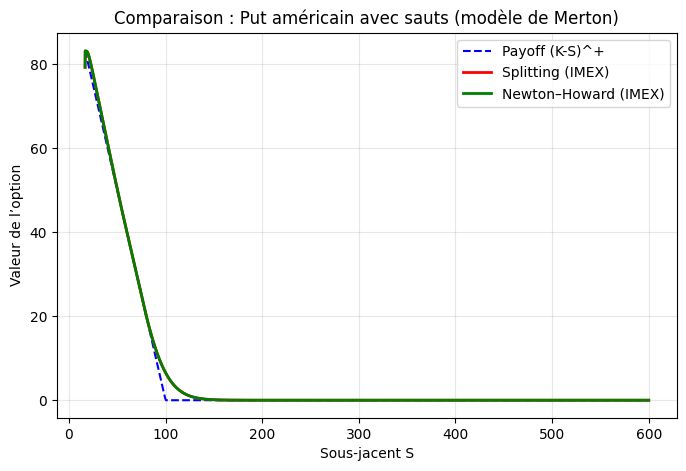

In [11]:
plt.figure(figsize=(8,5))
plt.plot(merton_put.S_vec, merton_put.payoff_f(merton_put.S_vec),
         'b--', lw=1.5, label='Payoff (K-S)^+')
plt.plot(merton_put.S_vec, merton_put.price_vec, 
         'r', lw=2, label='Splitting (IMEX)')

price_nh, _ = merton_put.PDE_NewtonHoward(Nspace=400, Ntime=300)
plt.plot(merton_put.S_vec, merton_put.price_vec,
         'g', lw=2, label='Newton–Howard (IMEX)')

plt.xlabel("Sous-jacent S")
plt.ylabel("Valeur de l’option")
plt.title("Comparaison : Put américain avec sauts (modèle de Merton)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


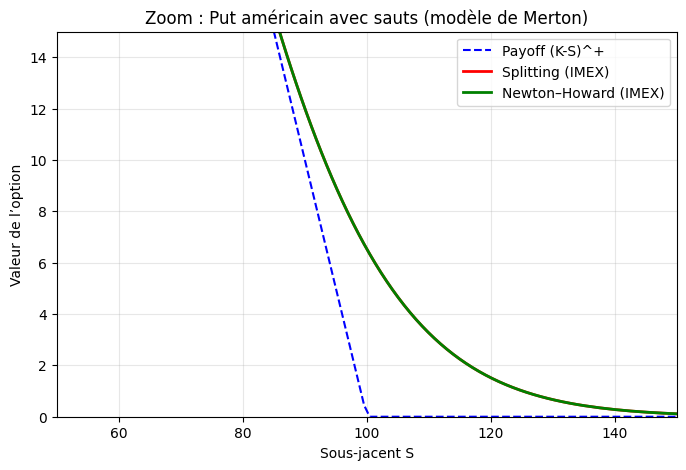

In [12]:
plt.figure(figsize=(8,5))
plt.plot(merton_put.S_vec, merton_put.payoff_f(merton_put.S_vec),
         'b--', lw=1.5, label='Payoff (K-S)^+')
plt.plot(merton_put.S_vec, merton_put.mesh[:,0], 'r', lw=2, label='Splitting (IMEX)')

price_nh, _ = merton_put.PDE_NewtonHoward(Nspace=400, Ntime=300)
plt.plot(merton_put.S_vec, merton_put.mesh[:,0], 'g', lw=2, label='Newton–Howard (IMEX)')

plt.xlim(50, 150)   # <-- zoom horizontal sur la zone autour du strike
plt.ylim(0, 15)     # <-- zoom vertical pour mieux distinguer les courbes
plt.xlabel("Sous-jacent S")
plt.ylabel("Valeur de l’option")
plt.title("Zoom : Put américain avec sauts (modèle de Merton)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

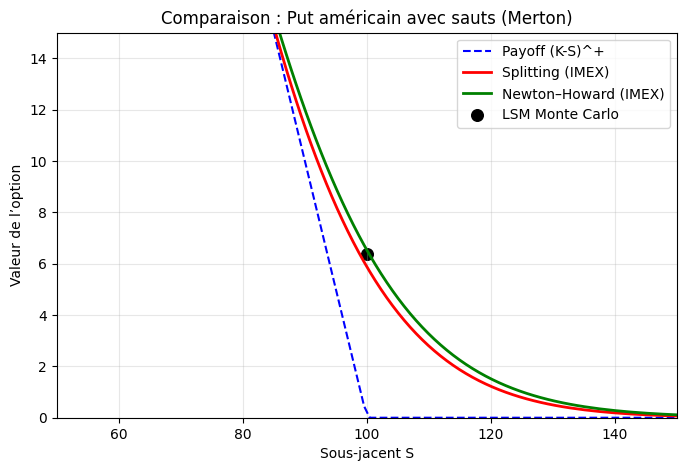

In [13]:
plt.figure(figsize=(8,5))
plt.plot(merton_put.S_vec, merton_put.payoff_f(merton_put.S_vec),
         'b--', lw=1.5, label='Payoff (K-S)^+')

price_split = merton_put.PDE_IMEX_splitting(Nspace=400, Ntime=300)
plt.plot(merton_put.S_vec, merton_put.price_vec, 'r', lw=2, label='Splitting (IMEX)')

price_nh, _ = merton_put.PDE_NewtonHoward(Nspace=400, Ntime=300)
plt.plot(merton_put.S_vec, merton_put.price_vec, 'g', lw=2, label='Newton–Howard (IMEX)')

# Point LSM Monte Carlo
price_lsm = merton_put.LSM_price(N_paths=20000, N_steps=100)
plt.scatter([merton_put.S0], [price_lsm], color='black', s=70, marker='o', label='LSM Monte Carlo')

plt.xlim(50, 150)
plt.ylim(0, 15)
plt.xlabel("Sous-jacent S")
plt.ylabel("Valeur de l’option")
plt.title("Comparaison : Put américain avec sauts (Merton)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()